In [1]:
import geopandas as gpd
import osmnx as ox
import pyregeon

In [2]:
agglom_extent_filepath = "../data/raw/zurich-extent.gpkg"
lake_nominatim_query = "Zürichsee"

dst_res = 100
dst_filepath = "../data/processed/regular-grid.gpkg"

In [3]:
# Parameters
agglom_extent_filepath = "data/processed/zurich-lcs-extent.gpkg"
dst_res = 100
dst_filepath = "data/processed/regular-grid.gpkg"


In [4]:
agglom_extent_gdf = gpd.read_file(agglom_extent_filepath)

In [5]:
grid_gser = pyregeon.generate_regular_grid_gser(
    agglom_extent_gdf["geometry"].iloc[:1], dst_res, geometry_type="point"
)
n_cells = len(grid_gser)

# ACHTUNG: drop the cells that fall on the lake. Their land use predictors are
# degenerate - no buildings, no canopy, zero distance to the lake and flat terrain at
# lake level - so they form a tight extreme cluster in predictor space that distorts the
# feature-space diagnostics, and a land use regression has nothing to say about air
# temperature over open water in the first place
lake_gser = ox.geocode_to_gdf(lake_nominatim_query).to_crs(agglom_extent_gdf.crs)[
    "geometry"
]
grid_gser = grid_gser[~grid_gser.within(lake_gser.union_all())]
print(f"dropped {n_cells - len(grid_gser)} of {n_cells} cells falling on the lake")

dropped 806 of 16078 cells falling on the lake


15272 prediction cells


<Axes: >

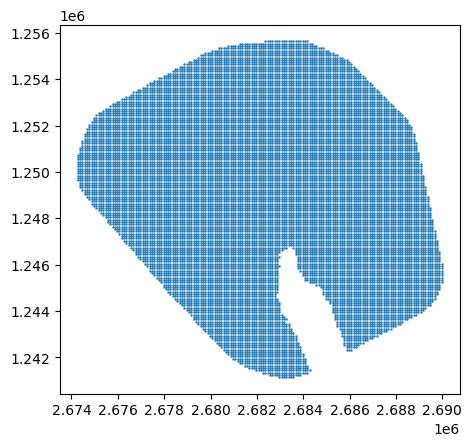

In [6]:
print(f"{len(grid_gser)} prediction cells")
grid_gser.plot(markersize=0.5)

In [7]:
grid_gser.to_file(dst_filepath)